In [7]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [8]:
# Run this in a Colab cell
!pip install torch-scatter torch-sparse torch-geometric -f https://data.pyg.org/whl/torch-2.0.0+cu118.html


Looking in links: https://data.pyg.org/whl/torch-2.0.0+cu118.html


In [9]:
# import os
# import glob
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torchvision import transforms
# from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
# from torch.utils.data import DataLoader, Dataset, Subset
# from sklearn.model_selection import train_test_split
# from PIL import Image
# from torch_geometric.data import Data
# from torch_geometric.nn import GCNConv
# import matplotlib.pyplot as plt
# from tqdm import tqdm

# # Check for GPU
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 1. Image Preprocessing
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor()
# ])

# # 2. Custom Dataset
# class MushroomDataset(Dataset):
#     def __init__(self, root_dir, transform=None):
#         self.images = []
#         self.labels = []
#         self.transform = transform
#         self.classes = sorted(os.listdir(root_dir))
#         for idx, label in enumerate(self.classes):
#             for img_path in glob.glob(os.path.join(root_dir, label, "*.jpg")):
#                 self.images.append(img_path)
#                 self.labels.append(idx)

#     def __len__(self):
#         return len(self.images)

#     def __getitem__(self, idx):
#         img = Image.open(self.images[idx]).convert("RGB")
#         label = self.labels[idx]
#         if self.transform:
#             img = self.transform(img)
#         return img, label

# dataset = MushroomDataset(root_dir="/kaggle/input/split-dataset-of-fish/split dataset of fish/train", transform=transform)

# # 3. Train/Validation Split
# indices = list(range(len(dataset)))
# train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=dataset.labels, random_state=42)
# train_dataset = Subset(dataset, train_idx)
# val_dataset = Subset(dataset, val_idx)

# train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
# val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

# # 4. ConvNeXt Feature Extractor
# class ConvNeXtFeatureExtractor(nn.Module):
#     def __init__(self):
#         super().__init__()
#         model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
#         self.backbone = nn.Sequential(*list(model.features.children()))

#     def forward(self, x):
#         return self.backbone(x)  # (B, C, H, W)

# convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# # 5. Convert CNN feature map to graph
# def image_to_graph(features, label):
#     B, C, H, W = features.shape
#     graphs = []

#     for b in range(B):
#         feature_map = features[b]  # (C, H, W)
#         x = feature_map.permute(1, 2, 0).reshape(-1, C)  # (H*W, C)

#         # Grid edges
#         edges = []
#         for i in range(H):
#             for j in range(W):
#                 idx = i * W + j
#                 if i + 1 < H:
#                     edges.append((idx, idx + W))
#                     edges.append((idx + W, idx))
#                 if j + 1 < W:
#                     edges.append((idx, idx + 1))
#                     edges.append((idx + 1, idx))

#         edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
#         y = torch.tensor([label[b]], dtype=torch.long)

#         graphs.append(Data(x=x, edge_index=edge_index, y=y))

#     return graphs

# # 6. GCN Classifier
# class GCNClassifier(nn.Module):
#     def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
#         super().__init__()
#         self.conv1 = GCNConv(input_dim, hidden_dim)
#         self.conv2 = GCNConv(hidden_dim, hidden_dim)
#         self.fc = nn.Linear(hidden_dim, output_dim)

#     def forward(self, data):
#         x, edge_index = data.x, data.edge_index
#         x = F.relu(self.conv1(x, edge_index))
#         x = F.dropout(x, p=0.3, training=self.training)
#         x = F.relu(self.conv2(x, edge_index))
#         x = torch.mean(x, dim=0)  # Global mean pooling
#         return self.fc(x)

# gcn_model = GCNClassifier(input_dim=768, output_dim=len(dataset.classes)).to(device)
# optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
# criterion = nn.CrossEntropyLoss()

# # 7. Metrics Storage
# train_losses, val_losses = [], []
# train_accuracies, val_accuracies = [], []

# # 8. Training Loop
# for epoch in range(10):
#     gcn_model.train()
#     total_loss = 0
#     correct = 0
#     total = 0

#     for img_batch, label_batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
#         img_batch = img_batch.to(device)
#         label_batch = label_batch.to(device)

#         with torch.no_grad():
#             features = convnext_model(img_batch)

#         graphs = image_to_graph(features.cpu(), label_batch.cpu())

#         for graph in graphs:
#             graph = graph.to(device)
#             optimizer.zero_grad()
#             out = gcn_model(graph)
#             loss = criterion(out.unsqueeze(0), graph.y)
#             loss.backward()
#             optimizer.step()
#             total_loss += loss.item()
#             pred = out.argmax().item()
#             correct += int(pred == graph.y.item())
#             total += 1

#     train_acc = correct / total
#     train_losses.append(total_loss)
#     train_accuracies.append(train_acc)

#     # Validation
#     gcn_model.eval()
#     val_loss = 0
#     correct = 0
#     total = 0

#     for img_batch, label_batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Val"):
#         img_batch = img_batch.to(device)
#         label_batch = label_batch.to(device)

#         with torch.no_grad():
#             features = convnext_model(img_batch)
#             graphs = image_to_graph(features.cpu(), label_batch.cpu())

#             for graph in graphs:
#                 graph = graph.to(device)
#                 out = gcn_model(graph)
#                 loss = criterion(out.unsqueeze(0), graph.y)
#                 val_loss += loss.item()
#                 pred = out.argmax().item()
#                 correct += int(pred == graph.y.item())
#                 total += 1

#     val_acc = correct / total
#     val_losses.append(val_loss)
#     val_accuracies.append(val_acc)

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# # 9. Plotting Loss & Accuracy
# epochs = range(1, len(train_losses) + 1)
# plt.figure(figsize=(12, 5))

# # Loss plot
# plt.subplot(1, 2, 1)
# plt.plot(epochs, train_losses, label="Train Loss")
# plt.plot(epochs, val_losses, label="Val Loss")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.title("Loss Over Epochs")
# plt.legend()

# # Accuracy plot
# plt.subplot(1, 2, 2)
# plt.plot(epochs, train_accuracies, label="Train Accuracy")
# plt.plot(epochs, val_accuracies, label="Val Accuracy")
# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.title("Accuracy Over Epochs")
# plt.legend()

# plt.tight_layout()
# plt.show()


***** gobal mean pooling *****

In [10]:
# import os
# import glob
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torchvision import transforms
# from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
# from torch.utils.data import DataLoader, Dataset, Subset
# from sklearn.model_selection import train_test_split
# from PIL import Image
# from torch_geometric.data import Data
# from torch_geometric.nn import GCNConv
# import matplotlib.pyplot as plt
# from tqdm import tqdm
# import seaborn as sns
# import numpy as np
# from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
# from sklearn.preprocessing import label_binarize

# # Check for GPU
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 1. Image Preprocessing
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor()
# ])

# # 2. Custom Dataset
# class MushroomDataset(Dataset):
#     def __init__(self, root_dir, transform=None):
#         self.images = []
#         self.labels = []
#         self.transform = transform
#         self.classes = sorted(os.listdir(root_dir))
#         for idx, label in enumerate(self.classes):
#             for img_path in glob.glob(os.path.join(root_dir, label, "*.jpg")):
#                 self.images.append(img_path)
#                 self.labels.append(idx)

#     def __len__(self):
#         return len(self.images)

#     def __getitem__(self, idx):
#         img = Image.open(self.images[idx]).convert("RGB")
#         label = self.labels[idx]
#         if self.transform:
#             img = self.transform(img)
#         return img, label

# dataset = MushroomDataset(root_dir="/kaggle/input/split-dataset-of-fish/split dataset of fish/train", transform=transform)

# # 3. Train/Validation Split
# indices = list(range(len(dataset)))
# train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=dataset.labels, random_state=42)
# train_dataset = Subset(dataset, train_idx)
# val_dataset = Subset(dataset, val_idx)

# train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
# val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

# # 4. ConvNeXt Feature Extractor
# class ConvNeXtFeatureExtractor(nn.Module):
#     def __init__(self):
#         super().__init__()
#         model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
#         self.backbone = nn.Sequential(*list(model.features.children()))

#     def forward(self, x):
#         return self.backbone(x)  # (B, C, H, W)

# convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# # 5. Convert CNN feature map to graph
# def image_to_graph(features, label):
#     B, C, H, W = features.shape
#     graphs = []

#     for b in range(B):
#         feature_map = features[b]  # (C, H, W)
#         x = feature_map.permute(1, 2, 0).reshape(-1, C)  # (H*W, C)

#         # Grid edges
#         edges = []
#         for i in range(H):
#             for j in range(W):
#                 idx = i * W + j
#                 if i + 1 < H:
#                     edges.append((idx, idx + W))
#                     edges.append((idx + W, idx))
#                 if j + 1 < W:
#                     edges.append((idx, idx + 1))
#                     edges.append((idx + 1, idx))

#         edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
#         y = torch.tensor([label[b]], dtype=torch.long)

#         graphs.append(Data(x=x, edge_index=edge_index, y=y))

#     return graphs

# # 6. GCN Classifier
# class GCNClassifier(nn.Module):
#     def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
#         super().__init__()
#         self.conv1 = GCNConv(input_dim, hidden_dim)
#         self.conv2 = GCNConv(hidden_dim, hidden_dim)
#         self.fc = nn.Linear(hidden_dim, output_dim)

#     def forward(self, data):
#         x, edge_index = data.x, data.edge_index
#         x = F.relu(self.conv1(x, edge_index))
#         x = F.dropout(x, p=0.3, training=self.training)
#         x = F.relu(self.conv2(x, edge_index))
#         x = torch.mean(x, dim=0)  # Global mean pooling
#         return self.fc(x)

# gcn_model = GCNClassifier(input_dim=768, output_dim=len(dataset.classes)).to(device)
# optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
# criterion = nn.CrossEntropyLoss()

# # 7. Metrics Storage
# train_losses, val_losses = [], []
# train_accuracies, val_accuracies = [], []

# # 8. Training Loop
# for epoch in range(10):
#     gcn_model.train()
#     total_loss = 0
#     correct = 0
#     total = 0

#     for img_batch, label_batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
#         img_batch = img_batch.to(device)
#         label_batch = label_batch.to(device)

#         with torch.no_grad():
#             features = convnext_model(img_batch)

#         graphs = image_to_graph(features.cpu(), label_batch.cpu())

#         for graph in graphs:
#             graph = graph.to(device)
#             optimizer.zero_grad()
#             out = gcn_model(graph)
#             loss = criterion(out.unsqueeze(0), graph.y)
#             loss.backward()
#             optimizer.step()
#             total_loss += loss.item()
#             pred = out.argmax().item()
#             correct += int(pred == graph.y.item())
#             total += 1

#     train_acc = correct / total
#     train_losses.append(total_loss)
#     train_accuracies.append(train_acc)

#     # Validation
#     gcn_model.eval()
#     val_loss = 0
#     correct = 0
#     total = 0

#     for img_batch, label_batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Val"):
#         img_batch = img_batch.to(device)
#         label_batch = label_batch.to(device)

#         with torch.no_grad():
#             features = convnext_model(img_batch)
#             graphs = image_to_graph(features.cpu(), label_batch.cpu())

#             for graph in graphs:
#                 graph = graph.to(device)
#                 out = gcn_model(graph)
#                 loss = criterion(out.unsqueeze(0), graph.y)
#                 val_loss += loss.item()
#                 pred = out.argmax().item()
#                 correct += int(pred == graph.y.item())
#                 total += 1

#     val_acc = correct / total
#     val_losses.append(val_loss)
#     val_accuracies.append(val_acc)

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# # 9. Final Evaluation with Metrics
# all_preds = []
# all_labels = []

# for img_batch, label_batch in tqdm(val_loader, desc="Final Metrics"):
#     img_batch = img_batch.to(device)
#     label_batch = label_batch.to(device)

#     with torch.no_grad():
#         features = convnext_model(img_batch)
#         graphs = image_to_graph(features.cpu(), label_batch.cpu())

#         for i, graph in enumerate(graphs):
#             graph = graph.to(device)
#             out = gcn_model(graph)
#             pred = out.argmax().item()
#             true = graph.y.item()
#             all_preds.append(pred)
#             all_labels.append(true)

# # Confusion Matrix
# y_true = np.array(all_labels)
# y_pred = np.array(all_preds)

# plt.figure(figsize=(8, 6))
# cm = confusion_matrix(y_true, y_pred)
# sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=dataset.classes, yticklabels=dataset.classes)
# plt.xlabel("Predicted")
# plt.ylabel("True")
# plt.title("Confusion Matrix")
# plt.show()

# # Classification Report
# print("Classification Report:")
# print(classification_report(y_true, y_pred, target_names=dataset.classes))

# # ROC Curve
# n_classes = len(dataset.classes)
# y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
# y_pred_prob = np.zeros((len(y_pred), n_classes))

# counter = 0
# for img_batch, label_batch in tqdm(val_loader, desc="ROC Probabilities"):
#     img_batch = img_batch.to(device)
#     label_batch = label_batch.to(device)

#     with torch.no_grad():
#         features = convnext_model(img_batch)
#         graphs = image_to_graph(features.cpu(), label_batch.cpu())

#         for graph in graphs:
#             graph = graph.to(device)
#             out = gcn_model(graph)
#             probs = F.softmax(out, dim=0).cpu().numpy()
#             y_pred_prob[counter] = probs
#             counter += 1

# # Plot ROC Curve
# plt.figure(figsize=(10, 8))
# for i in range(n_classes):
#     fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
#     roc_auc = auc(fpr, tpr)
#     plt.plot(fpr, tpr, label=f"{dataset.classes[i]} (AUC = {roc_auc:.2f})")

# plt.plot([0, 1], [0, 1], "k--")
# plt.xlim([0.0, 1.0])
# plt.ylim([0.0, 1.05])
# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("Multi-Class ROC Curve")
# plt.legend(loc="lower right")
# plt.grid()
# plt.show()

# # 10. Plotting Loss & Accuracy
# epochs = range(1, len(train_losses) + 1)
# plt.figure(figsize=(12, 5))

# # Loss plot
# plt.subplot(1, 2, 1)
# plt.plot(epochs, train_losses, label="Train Loss")
# plt.plot(epochs, val_losses, label="Val Loss")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.title("Loss Over Epochs")
# plt.legend()

# # Accuracy plot
# plt.subplot(1, 2, 2)
# plt.plot(epochs, train_accuracies, label="Train Accuracy")
# plt.plot(epochs, val_accuracies, label="Val Accuracy")
# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.title("Accuracy Over Epochs")
# plt.legend()

# plt.tight_layout()
# plt.show()


In [11]:
# # Final Train and Validation Accuracy
# final_train_acc = train_accuracies[-1]
# final_val_acc = val_accuracies[-1]

# print(f"\n✅ Final Train Accuracy: {final_train_acc * 100:.2f}%")
# print(f"✅ Final Validation Accuracy: {final_val_acc * 100:.2f}%")


**GLOBAL MAX POOLING**

Class counts:
01_Dascyllus_reticulatus: 12112
02_plectroglyphidodon_dickii: 2683
03_Chromis_chrysura: 3593
04_Amphiprion_clarkii: 4049
05_chaetodon_lunulatus: 2534
06_chaetodon_trifascial: 190
07_myripristis_kuntee: 450
08_Acanthurus_nigrofuscus: 218
09_hemigymnus_fasciatus: 241
10_Neoniphon_sammara: 299
11_Abudefduf_vaigiensis: 98
12_cathigaster_valentini: 147
13_pomacentrus_moluccensis: 181
14_Zebrasoma_scopas: 90
15_hemigymnus_melapterus: 42
16_lutjanus_fulvus: 206
17_Scolopsis_bilineata: 49
18_Scaridae: 56
19_pempheris_vanicolensis: 29
20_Zanclus_cornutus: 21
21_neoglyphidon_nigroris: 16
22_balistapus_undulatus: 41
23_siganus_fuscescen: 25


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth
100%|██████████| 109M/109M [00:00<00:00, 231MB/s] 
Epoch 1 - Val: 100%|██████████| 86/86 [00:55<00:00,  1.56it/s]


Epoch 1 | Train Loss: 3954.0490 | Train Acc: 0.9531 | Val Loss: 408.3565 | Val Acc: 0.9812


Epoch 2 - Val: 100%|██████████| 86/86 [00:35<00:00,  2.41it/s]


Epoch 2 | Train Loss: 1588.5240 | Train Acc: 0.9812 | Val Loss: 356.3488 | Val Acc: 0.9845


...

Epoch 9 - Val: 100%|██████████| 86/86 [00:36<00:00,  2.37it/s]


Epoch 9 | Train Loss: 932.9127 | Train Acc: 0.9935 | Val Loss: 763.0773 | Val Acc: 0.9879


Epoch 10 - Val: 100%|██████████| 86/86 [00:35<00:00,  2.41it/s]


Epoch 10 | Train Loss: 720.2126 | Train Acc: 0.9944 | Val Loss: 642.4785 | Val Acc: 0.9874


Final Metrics: 100%|██████████| 86/86 [00:35<00:00,  2.43it/s]


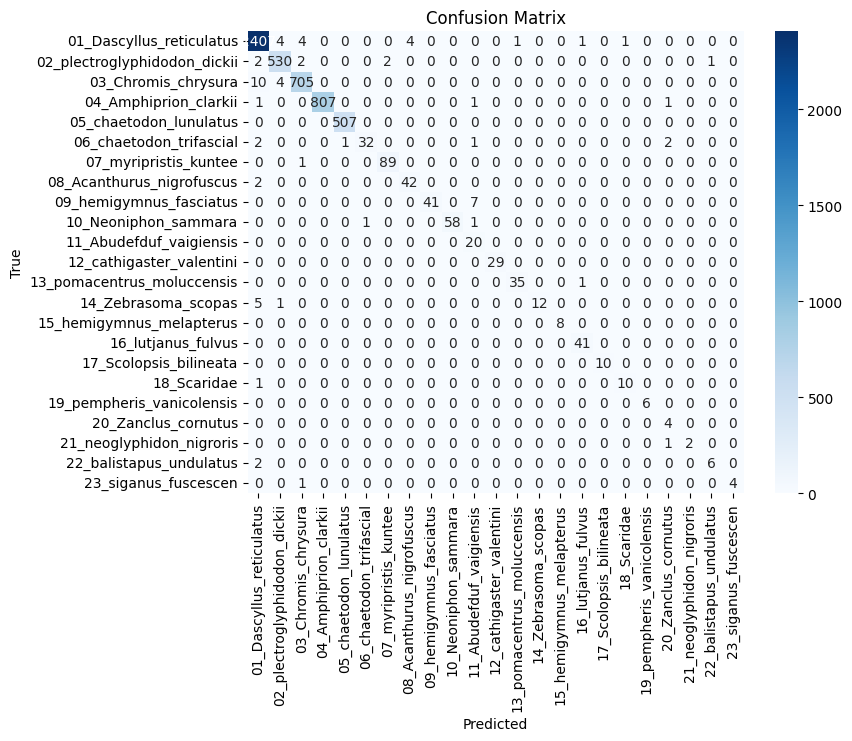

Classification Report:
                              precision    recall  f1-score   support

    01_Dascyllus_reticulatus       0.99      0.99      0.99      2422
02_plectroglyphidodon_dickii       0.98      0.99      0.99       537
         03_Chromis_chrysura       0.99      0.98      0.98       719
       04_Amphiprion_clarkii       1.00      1.00      1.00       810
      05_chaetodon_lunulatus       1.00      1.00      1.00       507
     06_chaetodon_trifascial       0.97      0.84      0.90        38
       07_myripristis_kuntee       0.98      0.99      0.98        90
   08_Acanthurus_nigrofuscus       0.91      0.95      0.93        44
     09_hemigymnus_fasciatus       1.00      0.85      0.92        48
        10_Neoniphon_sammara       1.00      0.97      0.98        60
     11_Abudefduf_vaigiensis       0.67      1.00      0.80        20
    12_cathigaster_valentini       1.00      1.00      1.00        29
  13_pomacentrus_moluccensis       0.97      0.97      0.97       

ROC Probabilities: 100%|██████████| 86/86 [00:35<00:00,  2.43it/s]


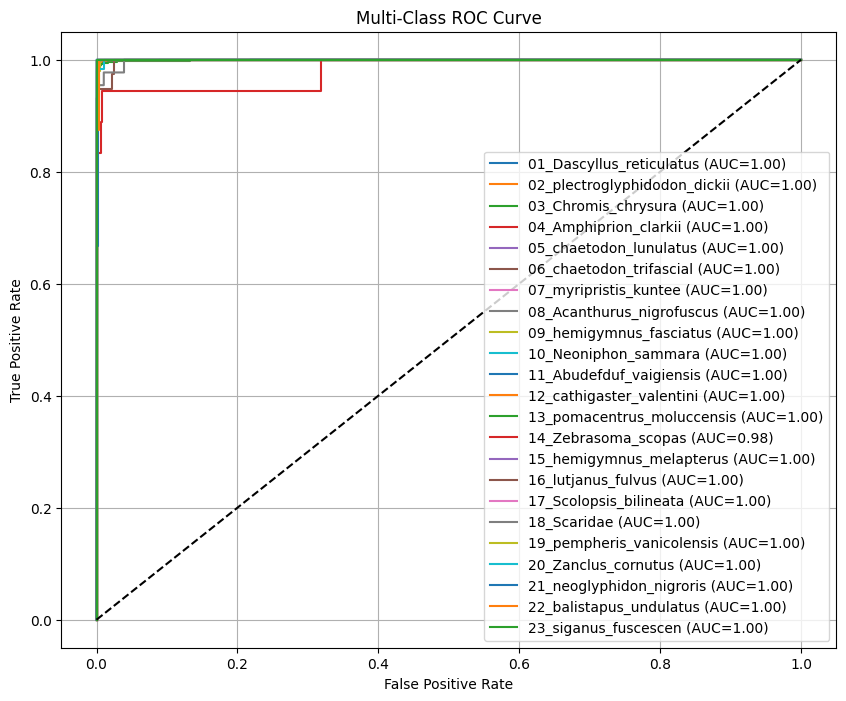

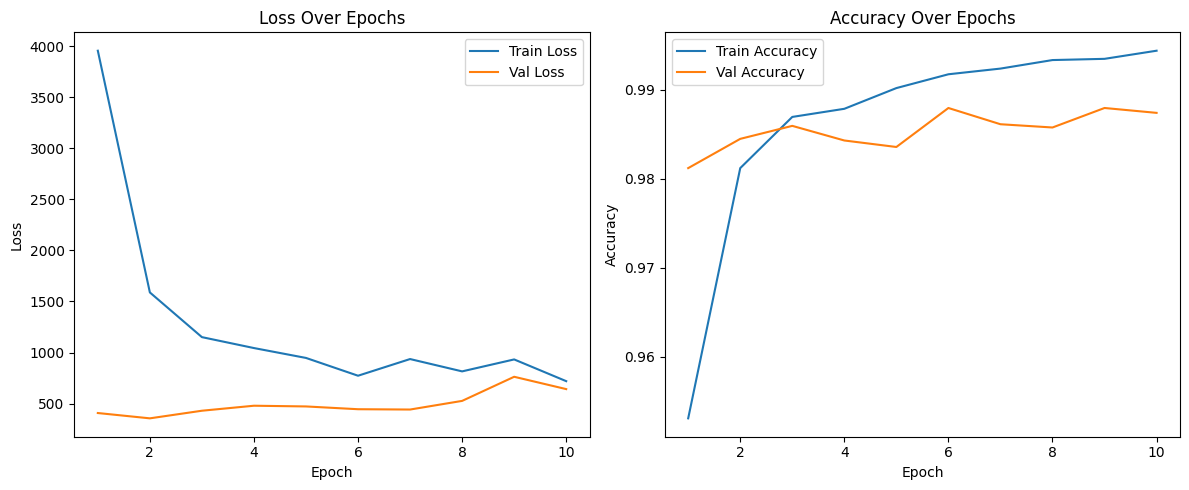

In [13]:
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
from PIL import Image
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, global_max_pool
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

# =============================
# Check for GPU
# =============================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =============================
# 1. Image Preprocessing
# =============================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# =============================
# 2. Custom Dataset
# =============================
class CustomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.images = []
        self.labels = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))

        # Support jpg and png
        exts = ["*.jpg", "*.png", "*.jpeg"]
        for idx, label in enumerate(self.classes):
            for ext in exts:
                files = glob.glob(os.path.join(root_dir, label, ext))
                for img_path in files:
                    self.images.append(img_path)
                    self.labels.append(idx)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

# =============================
# 3. Load Dataset + Verify
# =============================
root_dir = "/kaggle/input/comfish-2/fish4knowedge"  # ✅ Adjust
dataset = CustomDataset(root_dir=root_dir, transform=transform)

print("Class counts:")
for cls in dataset.classes:
    count = 0
    for ext in ["*.jpg", "*.png", "*.jpeg"]:
        count += len(glob.glob(os.path.join(root_dir, cls, ext)))
    print(f"{cls}: {count}")

if len(dataset) == 0:
    raise ValueError("❌ Dataset is empty. Please check dataset path and extensions.")

indices = list(range(len(dataset)))

# Safe stratified split
if len(set(dataset.labels)) > 1:
    train_idx, val_idx = train_test_split(
        indices, test_size=0.2, stratify=dataset.labels, random_state=42
    )
else:
    train_idx, val_idx = train_test_split(
        indices, test_size=0.2, random_state=42
    )

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

# =============================
# 4. ConvNeXt Feature Extractor
# =============================
class ConvNeXtFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(model.features.children()))

    def forward(self, x):
        return self.backbone(x)

convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# =============================
# 5. Convert CNN feature map to graph
# =============================
def image_to_graph(features, label):
    B, C, H, W = features.shape
    graphs = []

    for b in range(B):
        feature_map = features[b]
        x = feature_map.permute(1, 2, 0).reshape(-1, C)

        edges = []
        for i in range(H):
            for j in range(W):
                idx = i * W + j
                if i + 1 < H:
                    edges.append((idx, idx + W))
                    edges.append((idx + W, idx))
                if j + 1 < W:
                    edges.append((idx, idx + 1))
                    edges.append((idx + 1, idx))

        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        y = torch.tensor([label[b]], dtype=torch.long)
        graphs.append(Data(x=x, edge_index=edge_index, y=y))

    return graphs

# =============================
# 6. GCN Classifier
# =============================
class GCNClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, output_dim=len(dataset.classes)):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        batch = getattr(data, "batch", torch.zeros(x.size(0), dtype=torch.long, device=x.device))
        x = global_max_pool(x, batch)
        return self.fc(x)

gcn_model = GCNClassifier().to(device)
optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# =============================
# 7. Training Loop
# =============================
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(10):
    gcn_model.train()
    total_loss, correct, total = 0, 0, 0

    for img_batch, label_batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
        img_batch, label_batch = img_batch.to(device), label_batch.to(device)
        with torch.no_grad():
            features = convnext_model(img_batch)
        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for graph in graphs:
            graph = graph.to(device)
            optimizer.zero_grad()
            out = gcn_model(graph)
            loss = criterion(out, graph.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            pred = out.argmax().item()
            correct += int(pred == graph.y.item())
            total += 1

    train_acc = correct / total
    train_losses.append(total_loss)
    train_accuracies.append(train_acc)

    gcn_model.eval()
    val_loss, correct, total = 0, 0, 0
    for img_batch, label_batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Val"):
        img_batch, label_batch = img_batch.to(device), label_batch.to(device)
        with torch.no_grad():
            features = convnext_model(img_batch)
            graphs = image_to_graph(features.cpu(), label_batch.cpu())
            for graph in graphs:
                graph = graph.to(device)
                out = gcn_model(graph)
                loss = criterion(out, graph.y)
                val_loss += loss.item()
                pred = out.argmax().item()
                correct += int(pred == graph.y.item())
                total += 1

    val_acc = correct / total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    print(f"Epoch {epoch+1} | Train Loss: {total_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# =============================
# 8. Final Evaluation
# =============================
all_preds, all_labels = [], []
for img_batch, label_batch in tqdm(val_loader, desc="Final Metrics"):
    img_batch, label_batch = img_batch.to(device), label_batch.to(device)
    with torch.no_grad():
        features = convnext_model(img_batch)
        graphs = image_to_graph(features.cpu(), label_batch.cpu())
        for graph in graphs:
            graph = graph.to(device)
            out = gcn_model(graph)
            all_preds.append(out.argmax().item())
            all_labels.append(graph.y.item())

y_true, y_pred = np.array(all_labels), np.array(all_preds)

# Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=dataset.classes))

# ROC Curve
n_classes = len(dataset.classes)
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
y_pred_prob = np.zeros((len(y_pred), n_classes))
counter = 0
for img_batch, label_batch in tqdm(val_loader, desc="ROC Probabilities"):
    img_batch, label_batch = img_batch.to(device), label_batch.to(device)
    with torch.no_grad():
        features = convnext_model(img_batch)
        graphs = image_to_graph(features.cpu(), label_batch.cpu())
        for graph in graphs:
            graph = graph.to(device)
            out = gcn_model(graph)
            probs = F.softmax(out, dim=1).cpu().numpy()
            y_pred_prob[counter] = probs[0]
            counter += 1

plt.figure(figsize=(10, 8))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{dataset.classes[i]} (AUC={roc_auc:.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve"); plt.legend(); plt.grid()
plt.show()

# =============================
# 9. Plot Loss & Accuracy
# =============================
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Val Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss Over Epochs"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label="Train Accuracy")
plt.plot(epochs, val_accuracies, label="Val Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy Over Epochs"); plt.legend()

plt.tight_layout(); plt.show()


In [14]:
# # Final Train and Validation Accuracy
final_train_acc = train_accuracies[-1]
final_val_acc = val_accuracies[-1]

print(f"\n✅ Final Train Accuracy: {final_train_acc * 100:.2f}%")
print(f"✅ Final Validation Accuracy: {final_val_acc * 100:.2f}%")


✅ Final Train Accuracy: 99.44%
✅ Final Validation Accuracy: 98.74%
